In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
# Due to a Jupyter bug, the %matplotlib inline "magic" command needs to be in 
# its own cell. See:
# https://github.com/jupyter/notebook/issues/3385

%matplotlib inline

In [4]:
import numpy as np

import matplotlib
import matplotlib.pyplot as plt

# Adjust default font size so that labels are readable in plots
font = {'size': 18}
matplotlib.rc('font', **font)

# Robust Statistics

## Univariate Statistics

In [5]:
from scipy.stats import norm

def make_data_with_outliers(N=100, outlier_frac=0.02, outlier_scale=10.):
    Nout = int(outlier_frac*N)

    norms = norm.rvs(size=N-Nout)
    outliers = norm.rvs(scale=outlier_scale,size = Nout)
    data = np.hstack((norms, outliers))
    return data

In [6]:
data = make_data_with_outliers()

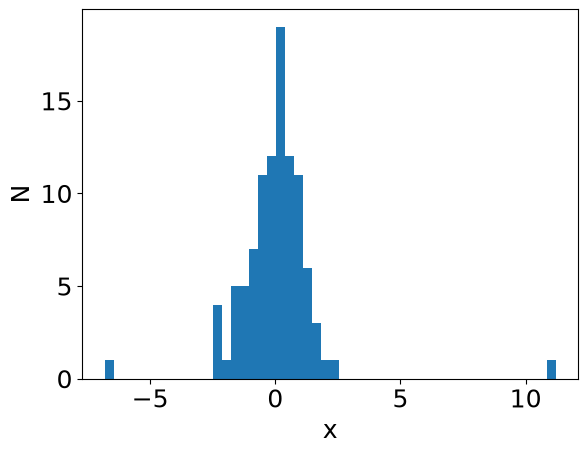

In [7]:
plt.hist(data, bins=50)
plt.xlabel('x')
plt.ylabel('N');

In [8]:
means = []
stds = []
medians = []
siqrs = []
pseudo_sigs = []
for i in range(1000):
    data = make_data_with_outliers(N=100, outlier_frac=0.02, outlier_scale=20.)
    means.append(np.mean(data))
    stds.append(np.std(data, ddof=1))
    medians.append(np.median(data))
    # Semi-interquartile range
    q75, q25 = np.percentile(data, [75 ,25])
    siqr = (q75 - q25)/2.
    siqrs.append(siqr)    
    q84, q16 = np.percentile(data, [84 ,16])
    pseudo_sig = (q84 - q16)/2.
    pseudo_sigs.append(pseudo_sig)

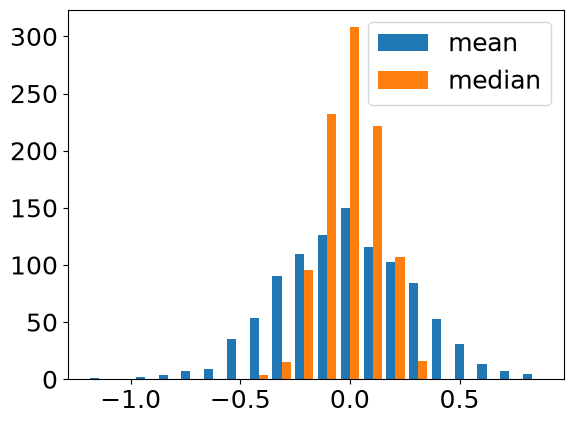

In [9]:
plt.hist([means, medians], bins=20, label=['mean','median'])
plt.legend();

Whereas for a Gaussian parent distribution, the standard deviation of the median is 1.25 times larger than that of the mean, in this case it is significantly smaller. 

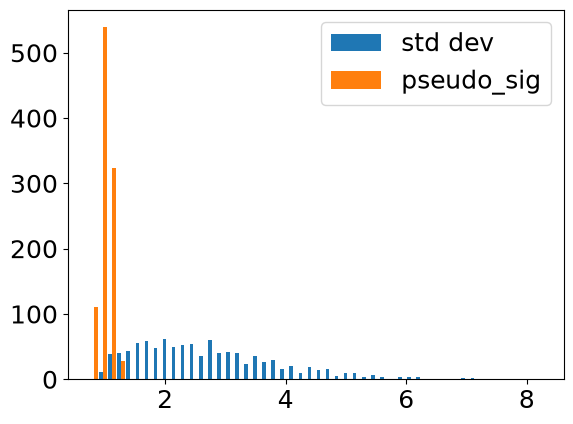

In [10]:
plt.hist([stds, pseudo_sigs], bins=50, label=['std dev','pseudo_sig'])
plt.legend();

The difference is even worse here because of the square factor when computing the stdev. So discrepancy is even worse than for mean vs median

## Robust Regression

There are several approaches:

1. Sigma clipping of outliers
2. Change your loss function or likelihood

### "$\sigma$ clipping"

A common idea is to reject 2, 3 or 4 $\sigma$ outliers. 

But which level to cut at?

This depends on your sample size. If the data are normally-distributed, then if $N=20$ you expect one $2\sigma$ outlier. If $N=1000$ you expect about 2 "$3\sigma$ outliers". 

So depending on the data set you might reject data beyond a level where you would expect only say 0.1 objects under the null hypothesis.  

### Regression with a different loss function

SDMMLA Section 8.9

Usually we have assumed that the residuals around the curve of best fit are Normally-distributed. This gives a log likelihood penalty that goes as the square of the residual. Clearly a very large residual will dominate the total penalty and the fit will try to minimize this outlier.

One can make different choices of loss function, such as the Huber loss function:

$$
\phi(t) = 
\begin{cases}
    \frac{1}{2} t^2 ,& \text{if } |t|\le c\\
    0,              & \text{otherwise}
\end{cases}
$$

where $t$ is a normalized residual

An alternative is to fit a full model, via maximum-likelihood, for all free parameters: the regression curve, plus the outlier fraction, outlier width etc.